In [ ]:
# Importing some libraries
import pandas as pd
import numpy as np
import seaborn as sns

In [ ]:
# Importing dataset that contains comments from a reddit post about student loan forgiveness
# https://www.reddit.com/r/FluentInFinance/comments/16gegy0/would_you_forgive_student_loan_debt_if_you_were/
reddit_data = pd.read_csv('sl_comments.csv')
reddit_data.head()

,Unnamed: 0,comment,ups,downs,created,date_time,date
0,0,r/FluentInFinance was created to discuss money...,1,0,1.694484e+09,2023-09-12 01:56:42,2023-09-12
1,2,No. quit positing this trash,5,0,1.694537e+09,2023-09-12 16:47:28,2023-09-12
2,3,This sub fucking sucks from these comments,126,0,1.694497e+09,2023-09-12 05:41:05,2023-09-12
3,4,"No, but I’d crack down on these college racket...",18,0,1.694501e+09,2023-09-12 06:43:15,2023-09-12
4,5,Yes 100%. I would also prosecute PPP fraud sev...,66,0,1.694498e+09,2023-09-12 05:55:16,2023-09-12


# **Data Pre-Processing**

**Removing Unnecessary Columns**

In [ ]:
# View the columns
reddit_data.columns

Index(['Unnamed: 0', 'comment', 'ups', 'downs', 'created', 'date_time',
       'date'],
      dtype='object')

In [ ]:
# Drop unnecessary column
reddit_data1 = reddit_data.drop(columns = ['Unnamed: 0', 'downs'], axis = 1)
reddit_data1.head()

,comment,ups,created,date_time,date
0,r/FluentInFinance was created to discuss money...,1,1.694484e+09,2023-09-12 01:56:42,2023-09-12
1,No. quit positing this trash,5,1.694537e+09,2023-09-12 16:47:28,2023-09-12
2,This sub fucking sucks from these comments,126,1.694497e+09,2023-09-12 05:41:05,2023-09-12
3,"No, but I’d crack down on these college racket...",18,1.694501e+09,2023-09-12 06:43:15,2023-09-12
4,Yes 100%. I would also prosecute PPP fraud sev...,66,1.694498e+09,2023-09-12 05:55:16,2023-09-12


**Removing symbols**

In [ ]:
# HERE, WE ARE REMOVING UNNECESSAARY SYMBOLS AND STOPWORDS
# This bunch of code relies heavily on regular expression (re). You can read more about it here: https://docs.python.org/3/library/re.html, https://www.analyticsvidhya.com/blog/2015/06/regular-expression-python/ and https://www.tutorialspoint.com/python3/python_reg_expressions.htm

# regular expresion (re) helps to find and replace pattern in a file or string.
# Some of the commonly use ones are: re.match(), re.search(), re.findall(), re.split(), re.sub()


import re                                                                       # Import  regular expression

import nltk                                                                     # Import Imports the Natural Language Toolkit library
nltk.download('stopwords')                                                      # Downloads a set of commonly used stopwords
from nltk.corpus import stopwords                                               # Imports the stopwords from the NLTK corpus
STOPWORDS = set(stopwords.words('english'))                                     # Creates a set of English stopwords from NLTK's corpus

#Reddit text cleaning
def reddit_clean (redd):                                                        # Create a function called reddit_clean
    redd = str(redd).lower()                                                    # Converts the text to lowercase
    redd = re.sub("'", "", redd)                                                # Removes single quotes
    redd = re.sub("@[A-Za-z0-9_]+","", redd)                                    # Removes patterns that start with '@'
    redd = re.sub("#[A-Za-z0-9_]+","", redd)                                    # Removes patterns that start with '#'
    redd = re.sub(r"www.\S+", "", redd)                                         # Removes URLs that start with 'www.'
    redd = re.sub(r"http\S+", "", redd)                                         # Removes URLs.
    redd = re.sub('[()!?]', ' ', redd)                                          # Replaces parentheses, exclamation marks, and question marks with spaces
    redd = re.sub('\[.*?\]',' ', redd)                                          # Removes text within square brackets
    redd = re.sub("[^a-z0-9]"," ", redd)                                        # Replaces non-alphanumeric characters with spaces.
    redd = re.sub(r"\b\w{1,3}\b"," ", redd)                                     # Removes words with less than 4 characters.
    redd = redd.split()                                                         # Splits the text into a list of words
    stopwords = STOPWORDS                                                       # Assigns the set of stopwords to a variable called stopwords
    redd = [w for w in redd if not w in stopwords]                              # Removes stopwords from the list of words
    redd = " ".join(word for word in redd)                                      # Joins the remaining words back into a string
    return redd                                                                 # Returns the cleaned text


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [ ]:
reddit_data1['comment'] = reddit_data1['comment'].apply(reddit_clean)           # Applies the reddit_clean function to clean the 'comment' column of the DataFrame reddit_data1
reddit_data1.head()                                                             # Displays the first few rows of the cleaned DataFrame

,comment,ups,created,date_time,date
0,fluentinfinance created discuss money investin...,1,1.694484e+09,2023-09-12 01:56:42,2023-09-12
1,quit positing trash,5,1.694537e+09,2023-09-12 16:47:28,2023-09-12
2,fucking sucks comments,126,1.694497e+09,2023-09-12 05:41:05,2023-09-12
3,crack college rackets putting people debt enco...,18,1.694501e+09,2023-09-12 06:43:15,2023-09-12
4,would also prosecute fraud severely people stu...,66,1.694498e+09,2023-09-12 05:55:16,2023-09-12


**Tokenization**

In [ ]:
sentence = "Hello, how are you today?"
words = sentence.split()  # Using default separator (whitespace)
print(words)

['Hello,', 'how', 'are', 'you', 'today?']


In [ ]:
# Tokenize the comments
tokenized_reddit_post = reddit_data1['comment'].apply(lambda x: x.split())
print(tokenized_reddit_post)

0       [fluentinfinance, created, discuss, money, inv...
1                                 [quit, positing, trash]
2                              [fucking, sucks, comments]
3       [crack, college, rackets, putting, people, deb...
4       [would, also, prosecute, fraud, severely, peop...
                              ...                        
2525                [crying, help, coming, anytime, soon]
2526    [help, coming, agreed, disagreed, whether, goo...
2527    [part, loans, deal, take, paycheck, defaulted,...
2528    [even, replying, words, saying, rolling, back,...
2529    [like, said, point, constitution, protect, peo...
Name: comment, Length: 2530, dtype: object


In [ ]:
# Same as
# def tokenize_text(comment):
#    return comment.split()
# reddit_data1['tokenized_comment'] = reddit_data1['comment'].apply(tokenize_text)
# print(reddit_data1['tokenized_comment'])

**Stemming**

In [ ]:
#Stemming is a rule-based process of stripping the suffixes (“ing”, “ly”, “es”, “s” etc) from a word.
#For example, For example – “play”, “player”, “played”, “plays” and “playing” are the different variations of the word – “play”.

from nltk.stem import PorterStemmer

stemmer = PorterStemmer()
tokenized_reddit_post = tokenized_reddit_post.apply(lambda x: [stemmer.stem(i) for i in x])
reddit_data1['tokenized']= tokenized_reddit_post
reddit_data1.head()

,comment,ups,created,date_time,date,tokenized
0,fluentinfinance created discuss money investin...,1,1.694484e+09,2023-09-12 01:56:42,2023-09-12,"[fluentinfin, creat, discuss, money, invest, f..."
1,quit positing trash,5,1.694537e+09,2023-09-12 16:47:28,2023-09-12,"[quit, posit, trash]"
2,fucking sucks comments,126,1.694497e+09,2023-09-12 05:41:05,2023-09-12,"[fuck, suck, comment]"
3,crack college rackets putting people debt enco...,18,1.694501e+09,2023-09-12 06:43:15,2023-09-12,"[crack, colleg, racket, put, peopl, debt, enco..."
4,would also prosecute fraud severely people stu...,66,1.694498e+09,2023-09-12 05:55:16,2023-09-12,"[would, also, prosecut, fraud, sever, peopl, s..."


In [ ]:
# Also same as
# from nltk.stem import PorterStemmer

# stemmer = PorterStemmer()

# def stem_words(word_list):
#    return [stemmer.stem(word) for word in word_list]

# tokenized_reddit_post = tokenized_reddit_post.apply(stem_words)

# reddit_data1['tokenized_and_stemmed'] = tokenized_reddit_post

# Print the updated DataFrame
# print(reddit_data1.head())


# **Word Cloud and Word Count**

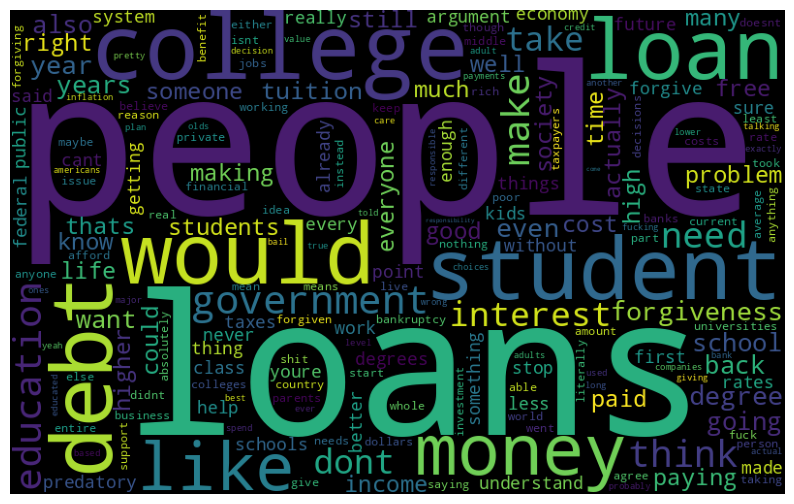

In [ ]:
import matplotlib.pyplot as plt
from wordcloud import WordCloud       # To generate word clouds
import collections                    # Collections module is used to count the frequency of words.

all_words = ' '.join([text for text in reddit_data1['comment']])      # Concatenates all the text data into a single string
count_word = collections.Counter(all_words.split())                   # Tokenize the all_words and count their frequencies

wordcloud = WordCloud(width=800, height=500)                          # width and height of the wordcloud in pixel
wordcloud.generate_from_frequencies(count_word)                       # generate the word cloud based on the word frequencies calculated earlier.
plt.figure(figsize=(10, 7))                                           # In inches
plt.imshow(wordcloud)
plt.axis("off")
plt.show()

In [ ]:
import itertools
import collections
#count the most words shown up in all_words
count_word = collections.Counter(all_words.split())
count_word.most_common(15)

[('people', 987),
 ('loans', 879),
 ('college', 624),
 ('student', 588),
 ('would', 574),
 ('debt', 572),
 ('loan', 567),
 ('money', 431),
 ('like', 374),
 ('government', 352),
 ('education', 337),
 ('make', 335),
 ('think', 308),
 ('need', 292),
 ('dont', 265)]

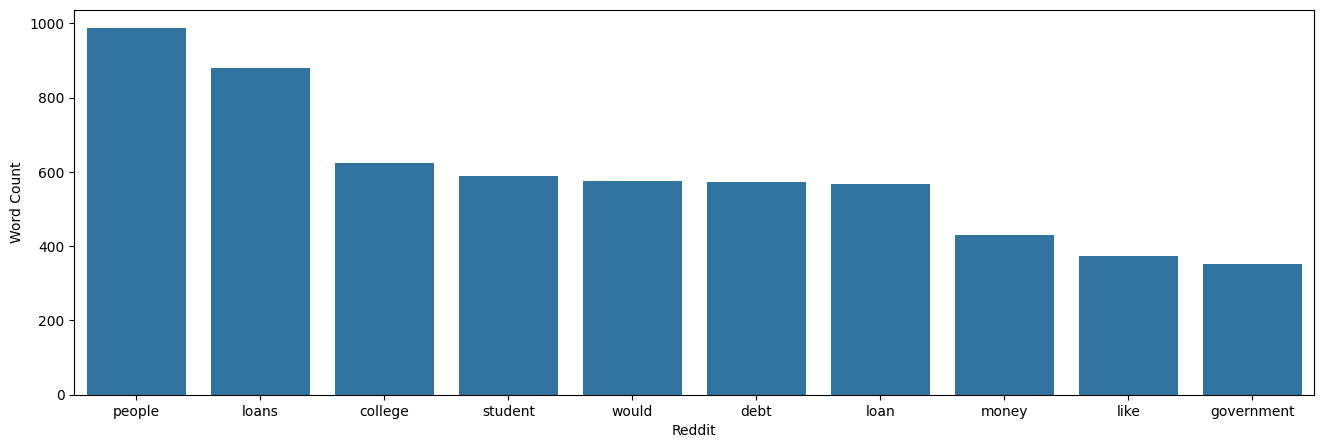

In [ ]:
# Make a bar chart of the top 10 neutral words

a = nltk.FreqDist(count_word)                       # Create a frequency distribution a from the counted objects in word_count
d = pd.DataFrame({'Reddit': list(a.keys()),
                  'Count': list(a.values())})
# selecting top 10 most frequent words
d = d.nlargest(columns="Count", n = 10)             # Select the top 10
plt.figure(figsize=(16,5))
ax = sns.barplot(data=d, x= "Reddit", y = "Count")
ax.set(ylabel = 'Word Count')                       # The code sets the label for the y-axis to 'Word Count'
plt.show()

# **Sentiment Analysis using Textblob**

In [ ]:
from textblob import TextBlob

# Example text
text = "I love coding with Python. It's fantastic!"

# Create a TextBlob object
blob = TextBlob(text)

In [ ]:
# Get sentiment polarity (range: -1 to 1, where -1 is negative, 0 is neutral, and 1 is positive)
blob.sentiment.polarity

0.5

In [ ]:
# Get sentiment subjectivity (range: 0 to 1, where 0 is objective and 1 is subjective)
blob.sentiment.subjectivity


0.75

In [ ]:
from textblob import TextBlob     # This is the first library we are using for the sentiment analysis.
#The sentiment function of textblob returns two properties, polarity, and subjectivity. Polarity is float which lies in the range of [-1,1] where 1 means positive statement
#and -1 means a negative statement.
#Subjective sentences generally refer to personal opinion, emotion or judgment whereas objective refers to factual information.
#Subjectivity is also a float which lies in the range of [0,1].

def get_polarity(text):
    analysis = TextBlob(text)
    return analysis.sentiment.polarity

def get_subjectivity(text):
    analysis = TextBlob(text)
    return analysis.sentiment.subjectivity

reddit_data1['polarity'] = reddit_data1['comment'].apply(get_polarity)
reddit_data1['subjectivity'] = reddit_data1['comment'].apply(get_subjectivity)
reddit_data1.head()

,comment,ups,created,date_time,date,tokenized,polarity,subjectivity
0,fluentinfinance created discuss money investin...,1,1.694484e+09,2023-09-12 01:56:42,2023-09-12,"[fluentinfin, creat, discuss, money, invest, f...",0.100000,0.100000
1,quit positing trash,5,1.694537e+09,2023-09-12 16:47:28,2023-09-12,"[quit, posit, trash]",0.000000,0.000000
2,fucking sucks comments,126,1.694497e+09,2023-09-12 05:41:05,2023-09-12,"[fuck, suck, comment]",-0.300000,0.300000
3,crack college rackets putting people debt enco...,18,1.694501e+09,2023-09-12 06:43:15,2023-09-12,"[crack, colleg, racket, put, peopl, debt, enco...",0.000000,0.100000
4,would also prosecute fraud severely people stu...,66,1.694498e+09,2023-09-12 05:55:16,2023-09-12,"[would, also, prosecut, fraud, sever, peopl, s...",-0.097222,0.180556


In [ ]:
# Create a function to classify the polarity
def analyze_sentiment(text):
    blob = TextBlob(text)
    sentiment_polarity = blob.sentiment.polarity
    if sentiment_polarity > 0:
        return 'Positive Sentiment'
    elif sentiment_polarity == 0:
        return 'Neutral Sentiment'
    else:
        return 'Negative Sentiment'

In [ ]:
# We create a sentiment column with the function created:
reddit_data1['sentiment'] = reddit_data1['comment'].apply(analyze_sentiment)
reddit_data1.head()

,comment,ups,created,date_time,date,tokenized,polarity,subjectivity,sentiment
0,fluentinfinance created discuss money investin...,1,1.694484e+09,2023-09-12 01:56:42,2023-09-12,"[fluentinfin, creat, discuss, money, invest, f...",0.100000,0.100000,Positive Sentiment
1,quit positing trash,5,1.694537e+09,2023-09-12 16:47:28,2023-09-12,"[quit, posit, trash]",0.000000,0.000000,Neutral Sentiment
2,fucking sucks comments,126,1.694497e+09,2023-09-12 05:41:05,2023-09-12,"[fuck, suck, comment]",-0.300000,0.300000,Negative Sentiment
3,crack college rackets putting people debt enco...,18,1.694501e+09,2023-09-12 06:43:15,2023-09-12,"[crack, colleg, racket, put, peopl, debt, enco...",0.000000,0.100000,Neutral Sentiment
4,would also prosecute fraud severely people stu...,66,1.694498e+09,2023-09-12 05:55:16,2023-09-12,"[would, also, prosecut, fraud, sever, peopl, s...",-0.097222,0.180556,Negative Sentiment


In [ ]:
# Create a new subjectivity column
reddit_data1['subjectivity2'] = np.where(reddit_data1['subjectivity'] > 0.5, 'Subjective', 'Objective')
reddit_data1.head()

,comment,ups,created,date_time,date,tokenized,polarity,subjectivity,sentiment,subjectivity2
0,fluentinfinance created discuss money investin...,1,1.694484e+09,2023-09-12 01:56:42,2023-09-12,"[fluentinfin, creat, discuss, money, invest, f...",0.100000,0.100000,Positive Sentiment,Objective
1,quit positing trash,5,1.694537e+09,2023-09-12 16:47:28,2023-09-12,"[quit, posit, trash]",0.000000,0.000000,Neutral Sentiment,Objective
2,fucking sucks comments,126,1.694497e+09,2023-09-12 05:41:05,2023-09-12,"[fuck, suck, comment]",-0.300000,0.300000,Negative Sentiment,Objective
3,crack college rackets putting people debt enco...,18,1.694501e+09,2023-09-12 06:43:15,2023-09-12,"[crack, colleg, racket, put, peopl, debt, enco...",0.000000,0.100000,Neutral Sentiment,Objective
4,would also prosecute fraud severely people stu...,66,1.694498e+09,2023-09-12 05:55:16,2023-09-12,"[would, also, prosecut, fraud, sever, peopl, s...",-0.097222,0.180556,Negative Sentiment,Objective


In [ ]:
# Counting the number of sentiment for each case of positive, negative and neutral.
reddit_data1['sentiment'].value_counts()

Positive Sentiment    1228
Neutral Sentiment      717
Negative Sentiment     585
Name: sentiment, dtype: int64

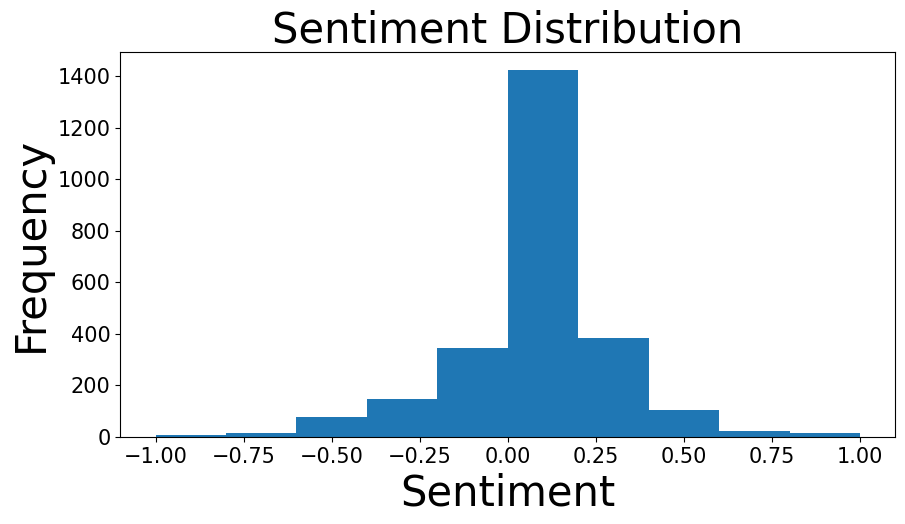

In [ ]:
# Bar chart of the sentiment
plt.figure(figsize=(10,5))
plt.xlabel('Sentiment', fontsize=30)
plt.xticks(fontsize=15)
plt.ylabel('Frequency', fontsize=30)
plt.yticks(fontsize=15)
plt.hist(reddit_data1['polarity'], bins=10)
plt.title('Sentiment Distribution', fontsize=30)
plt.show()

In [ ]:
# Counting the number of cases that fall within each subjectivity category
reddit_data1['subjectivity2'].value_counts()

Objective     1634
Subjective     896
Name: subjectivity2, dtype: int64

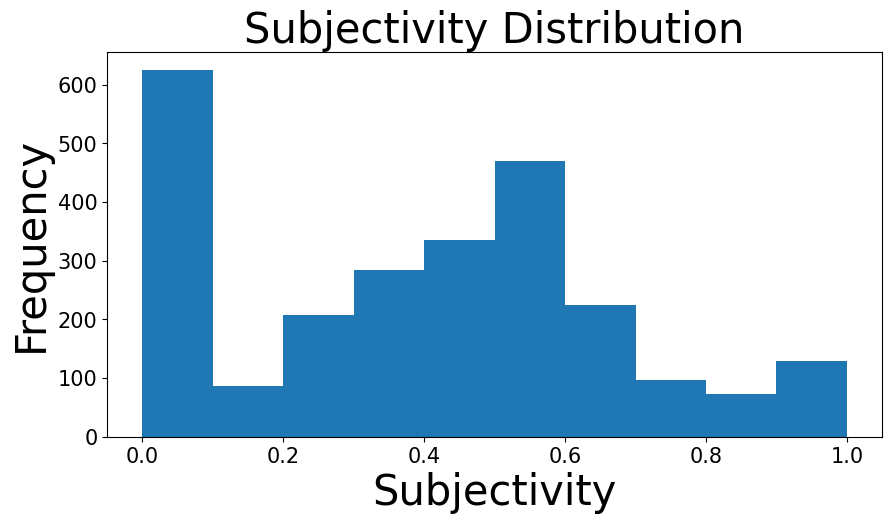

In [ ]:
# Bar chart of the subjectivity
plt.figure(figsize=(10,5))
plt.xlabel('Subjectivity', fontsize=30)
plt.xticks(fontsize=15)
plt.ylabel('Frequency', fontsize=30)
plt.yticks(fontsize=15)
plt.hist(reddit_data1['subjectivity'], bins=10)
plt.title('Subjectivity Distribution', fontsize=30)
plt.show()

In [ ]:
# Summary Statistics of polarity and subjectivity
pol_sub = reddit_data1[["polarity", "subjectivity"]]
pol_sub.describe()                    # Even though there are more positive sentiment sentences, overall the average polarity is around 0.06

,polarity,subjectivity
count,2530.000000,2530.000000
mean,0.056632,0.383589
std,0.227230,0.280602
min,-1.000000,0.000000
25%,0.000000,0.100000
50%,0.000000,0.409028
75%,0.175000,0.571429
max,1.000000,1.000000


In [ ]:
# Crosstabs
pd.crosstab(reddit_data1['sentiment'], reddit_data1['subjectivity2'])

subjectivity2,Objective,Subjective
sentiment,,
Negative Sentiment,280,305
Neutral Sentiment,685,32
Positive Sentiment,669,559
